# 01 · Meet the network

**Follow a source neuron from its original body ID to a modeled connection.**

This notebook loads the project's existing **14-neuron, 22-edge MaleCNS v1.0 flight-power fixture**. It is a deliberately selected teaching sample: the full Minecraft model retains 166,700 neurons and 25,582,938 edges. The small fixture makes every value inspectable on an ordinary laptop.

You will inspect the annotations, draw the actual weighted adjacency matrix, and distinguish the source anatomy from the assumptions added by the model. Nothing in this notebook starts Minecraft, downloads the full network, or measures a biological fly.

**Before you begin:** install the research environment using the [research quickstart](../docs/RESEARCH_QUICKSTART.md), select that Python environment in your notebook editor, and run the cells in order. [Current model card](../docs/MODEL_CARD.md).

In [1]:
import os
import sys
from pathlib import Path

# Works when launched from the project root or this notebooks/ directory.
ROOT = next(
    (
        path
        for path in (Path.cwd(), *Path.cwd().parents)
        if (path / "pyproject.toml").is_file()
        and (path / "research/example-v1/manifest.json").is_file()
    ),
    None,
)
if ROOT is None:
    raise RuntimeError("Open this notebook inside the NeuroCraft Fly source directory.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
DATASET = ROOT / "research/example-v1"
FIGURES = Path(
    os.environ.get("NEUROCRAFT_RESEARCH_OUTPUT", str(ROOT / "artifacts/research-notebooks/figures"))
)

In [2]:
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

from scripts.research_example import ABS_TOL, REL_TOL, load_dataset, load_graph, verify
from scripts.research_figures import export_figure, plot_network


def show_table(headers, rows):
    def clean(value):
        return str(value).replace("|", " / ").replace("\n", " ")

    lines = ["| " + " | ".join(headers) + " |", "| " + " | ".join(["---"] * len(headers)) + " |"]
    lines.extend("| " + " | ".join(clean(value) for value in row) + " |" for row in rows)
    display(Markdown("\n".join(lines)))

## Load and verify

The loader checks the fixture's pinned identity. `verify` checks the example's payload and code hashes, then regenerates its numerical results.

The notebooks use **numerical replay** with absolute tolerance `1e-12` and relative tolerance `1e-10` (`math.isclose` semantics), allowing small platform/libm differences only in declared floating-point values. Source IDs, configuration, code hashes, schemas, and the stored payload hashes remain exact. A failed check stops the notebook. After successful verification, `load_dataset(..., replay=False)` reads the verified tables without running the experiment a second time.

For the stricter same-platform check, run `uv run --locked python scripts/research_example.py verify`: the CLI defaults to **byte-exact replay**. Numerical replay and byte-exact replay are different checks; passing one is not a claim that the other passed.

In [3]:
graph = load_graph()
report = verify(DATASET, tolerant=True)
example = load_dataset(DATASET, replay=False)
tables = example["tables"]
manifest = example["manifest"]
assert len(graph.nodes) == 14 and len(graph.edges) == 22
print(f"Loaded {len(graph.nodes)} source neurons and {len(graph.edges)} directed source edges.")
print("Dataset:", manifest["example_id"])
print("Graph identity:", graph.manifest.runtime_identity_sha256)
print("Verification:", report["mode"])
print(f"Replay tolerances: absolute={ABS_TOL:g}, relative={REL_TOL:g}; identities remain exact.")

Loaded 14 source neurons and 22 directed source edges.
Dataset: malecns-flight-power-synthetic-pulses-v1
Graph identity: 49001caafff67ab5dfc303b169155136482b7574fd42e93736bdbbfa6f66fc07
Verification: numerical_replay
Replay tolerances: absolute=1e-12, relative=1e-10; identities remain exact.


## Read the annotations

A **body ID** identifies a source neuron. The dense index is only a local array position. Cell-type and side labels below are copied from the source; an empty cell means an annotation is missing. Roles describe this fixture's selection. They do not establish that these 14 cells are a complete behavioral circuit.

`annotation_source_row` points into the original source object named in the manifest, rather than a line in our example CSV.

In [4]:
show_table(
    [
        "Body ID",
        "Source type",
        "Side",
        "Selected roles",
        "Consensus transmitter",
        "Annotation source row",
    ],
    [
        [
            row["body_id"],
            row["type_name"],
            row["side"],
            row["roles"],
            row["consensus_nt"],
            row["annotation_source_row"],
        ]
        for row in tables["nodes"]
    ],
)

| Body ID | Source type | Side | Selected roles | Consensus transmitter | Annotation source row |
| --- | --- | --- | --- | --- | --- |
| 10026 | DNp18 | R | intermediate | acetylcholine | 19 |
| 10069 | AN07B004 | R | intermediate | acetylcholine | 58 |
| 10180 | AN02A002 | R | intermediate | glutamate | 165 |
| 10236 | DNg99 | R | intermediate | gaba | 218 |
| 10691 | WED203 | R | intermediate | gaba | 650 |
| 27143 | DNg07 | L | named:DNg07 | acetylcholine | 15756 |
| 28949 | DNg07 | R | named:DNg07 | acetylcholine | 17393 |
| 29142 | AMMC008 | L | intermediate | glutamate | 17573 |
| 73753 | AN07B003 | R | intermediate | acetylcholine | 56433 |
| 77185 | JO-EV3 | R | sensory | acetylcholine | 59342 |
| 536501 | AMMC008 | R | intermediate | glutamate | 161167 |
| 800241 | hg1 MN | L | motor | glutamate | 169326 |
| 800917 | hg1 MN | R | motor | glutamate | 169829 |
| 805722 | SNpp10 | L | sensory | acetylcholine | 173573 |

## Inspect all 22 source connections

The source supplies directed endpoints and raw contact counts. It does **not** supply a resolved functional sign for these edges: the canonical sign remains `unknown`.

For the numerical experiment, a declared coarse transmitter rule supplies modeled signs. Counts are normalized by each postsynaptic neuron's incoming count total. The `effective_weight` below is that normalized count multiplied by the assigned sign. Neither the sign nor the normalization is a measured synaptic efficacy.

In [5]:
original_edges = [row for row in tables["edges"] if row["condition"] == "original"]
assert len(original_edges) == 22
show_table(
    [
        "Pre → post body ID",
        "Source count",
        "Source row",
        "Source sign",
        "Modeled sign",
        "Effective weight",
    ],
    [
        [
            f"{row['body_pre']} → {row['body_post']}",
            row["raw_count"],
            row["source_row"],
            row["canonical_sign_status"],
            row["assigned_sign"],
            f"{float(row['effective_weight']):.5f}",
        ]
        for row in original_edges
    ],
)

| Pre → post body ID | Source count | Source row | Source sign | Modeled sign | Effective weight |
| --- | --- | --- | --- | --- | --- |
| 10691 → 10026 | 249 | 5163 | unknown | -1 | -0.97266 |
| 77185 → 10026 | 7 | 4474329 | unknown | 1 | 0.02734 |
| 10026 → 10069 | 25 | 746097 | unknown | 1 | 0.10638 |
| 10180 → 10069 | 210 | 8535 | unknown | -1 | -0.89362 |
| 805722 → 10180 | 43 | 299920 | unknown | 1 | 1.00000 |
| 10026 → 10236 | 6 | 5631514 | unknown | 1 | 0.06977 |
| 27143 → 10236 | 28 | 626877 | unknown | 1 | 0.32558 |
| 29142 → 10236 | 52 | 207105 | unknown | -1 | -0.60465 |
| 27143 → 10691 | 13 | 1835163 | unknown | 1 | 0.04545 |
| 28949 → 10691 | 25 | 732967 | unknown | 1 | 0.08741 |
| 29142 → 10691 | 248 | 5273 | unknown | -1 | -0.86713 |
| 10069 → 27143 | 26 | 674441 | unknown | 1 | 0.59091 |
| 536501 → 27143 | 18 | 1172800 | unknown | -1 | -0.40909 |
| 10069 → 28949 | 24 | 801690 | unknown | 1 | 0.45283 |
| 29142 → 28949 | 29 | 572925 | unknown | -1 | -0.54717 |
| 536501 → 29142 | 104 | 50613 | unknown | -1 | -1.00000 |
| 10026 → 73753 | 53 | 201202 | unknown | 1 | 0.41732 |
| 10236 → 73753 | 74 | 105127 | unknown | -1 | -0.58268 |
| 29142 → 536501 | 122 | 34822 | unknown | -1 | -0.78205 |
| 77185 → 536501 | 34 | 450501 | unknown | 1 | 0.21795 |
| 73753 → 800241 | 48 | 238705 | unknown | 1 | 1.00000 |
| 10026 → 800917 | 78 | 92518 | unknown | 1 | 1.00000 |

## See the retained structure

Each column is a presynaptic neuron; each row is a postsynaptic neuron. Color encodes the **unmodified raw source count**, on a linear scale starting at zero. Blank connections have zero retained weight. This is a graph matrix, not an anatomical image or a spatial map of a fly brain. Body IDs are ordered numerically, matching `nodes.csv`.

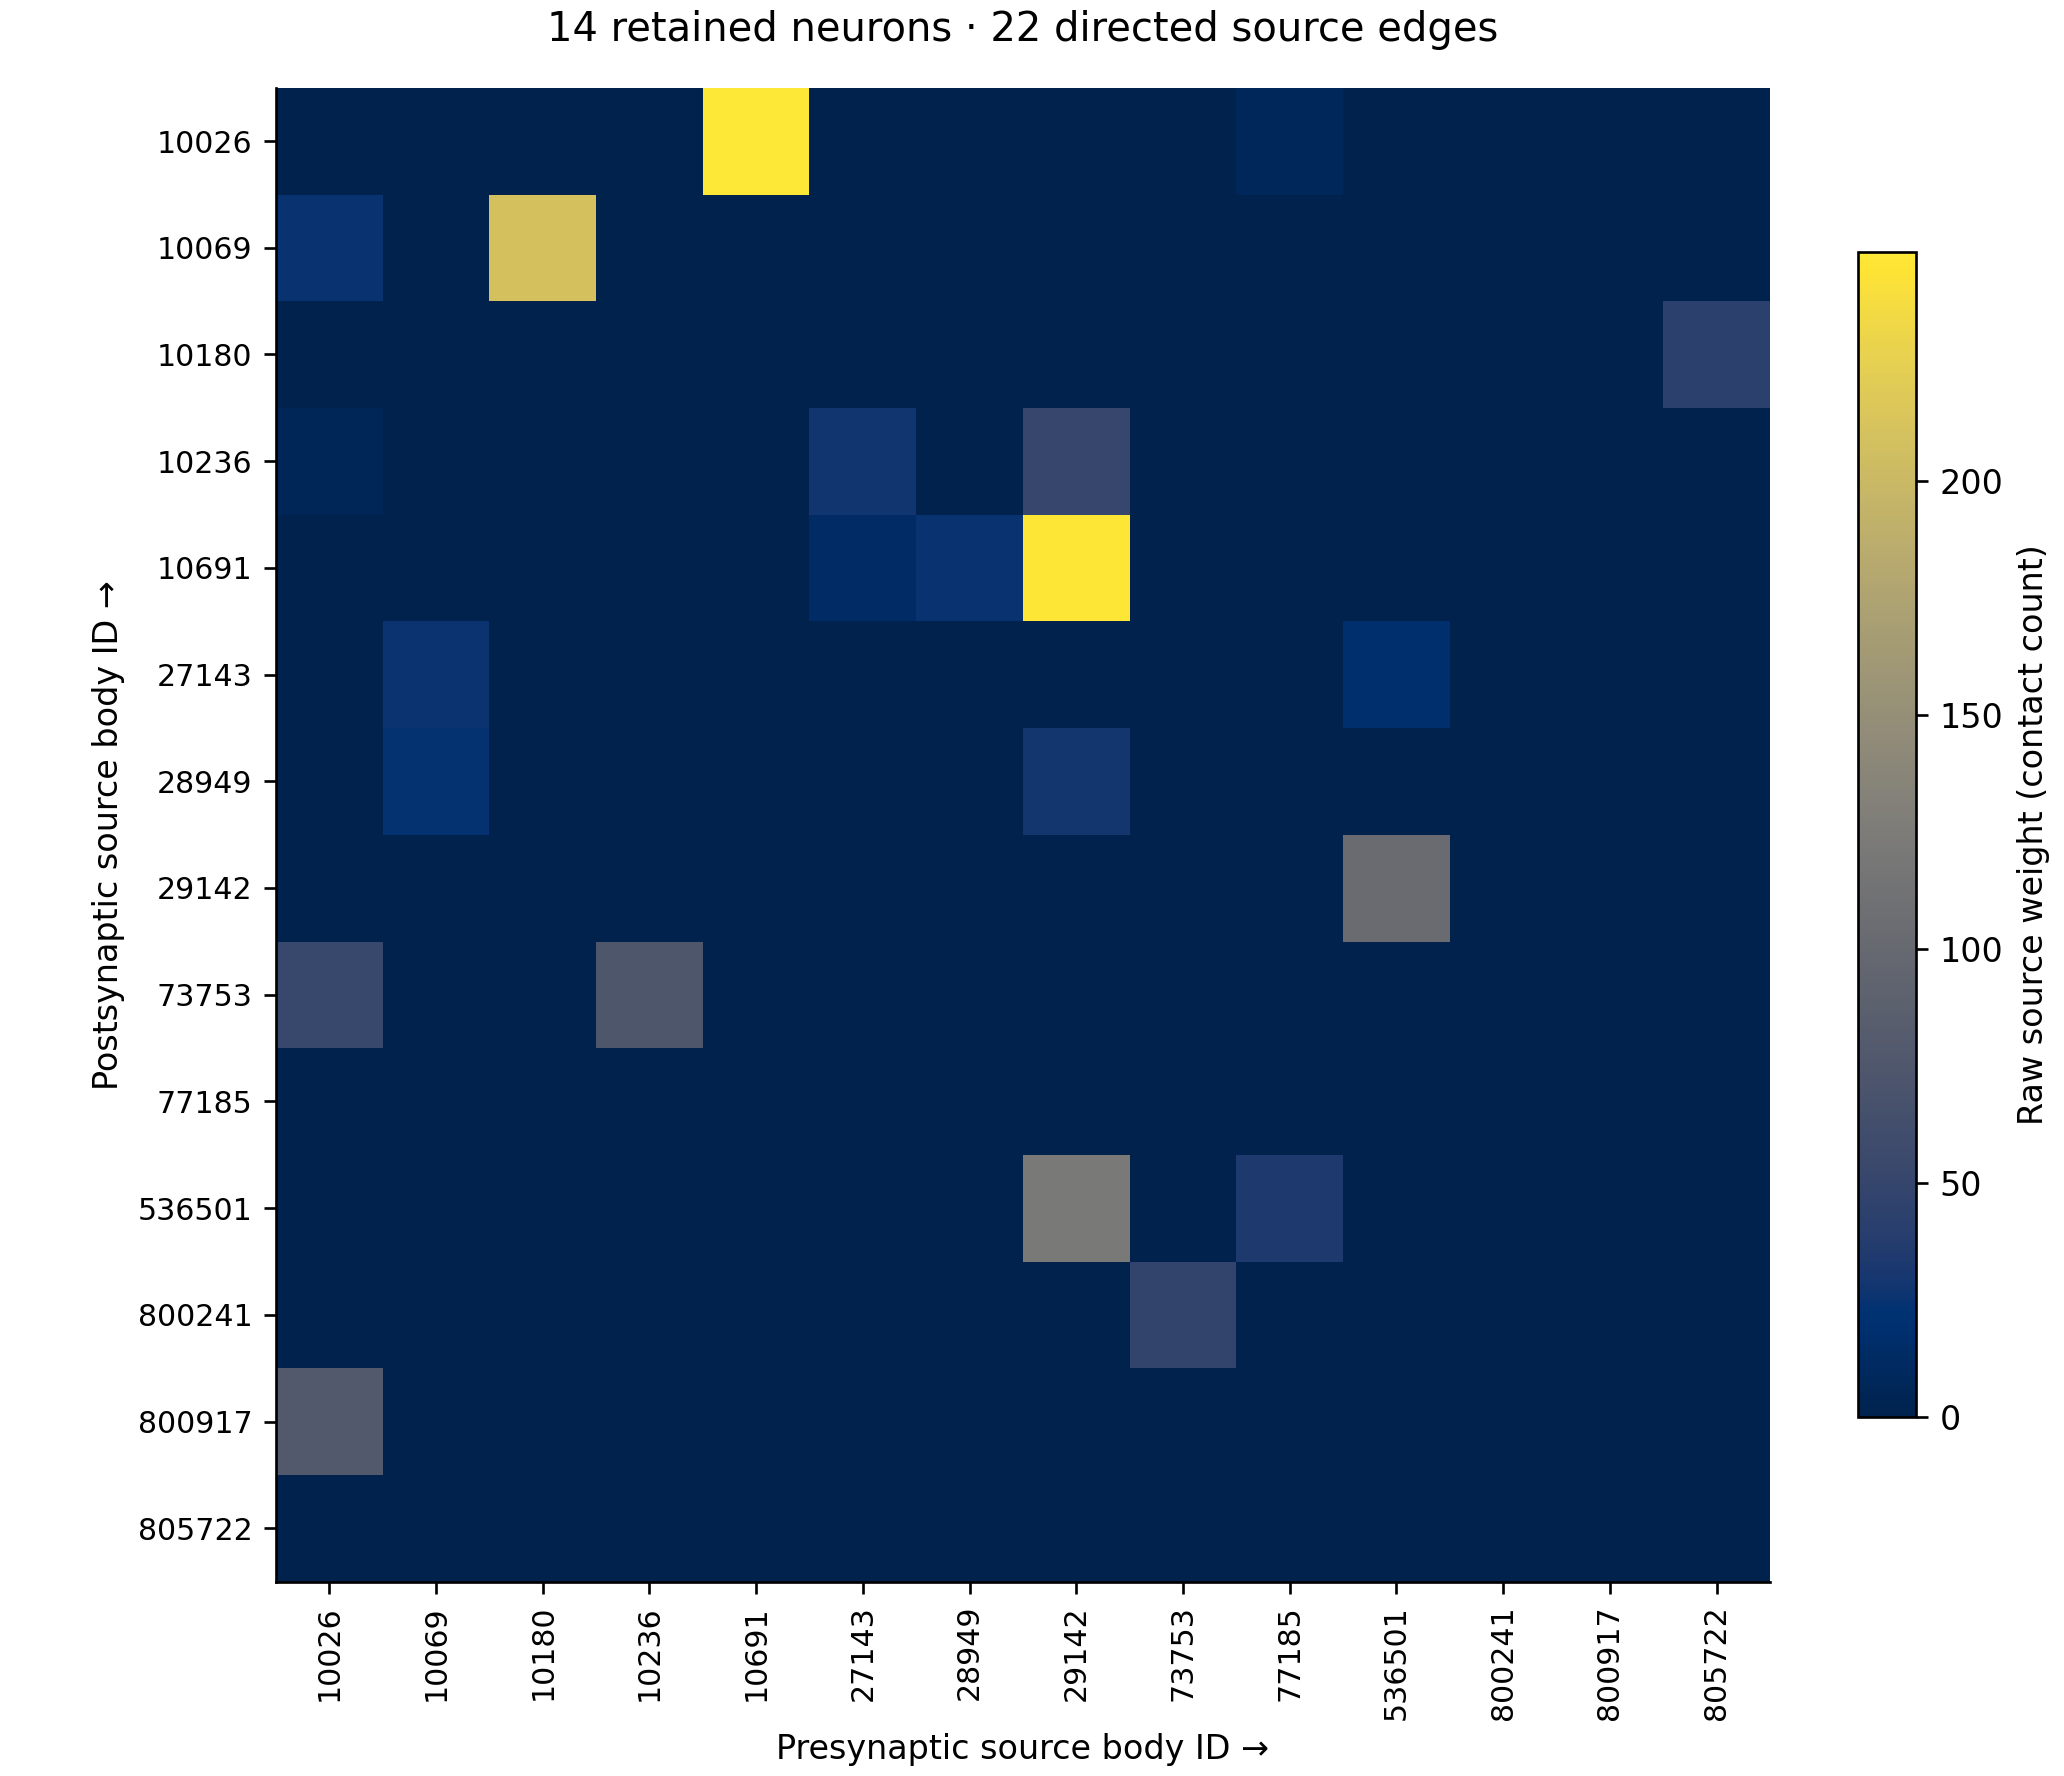

Saved 01_source_connectivity.svg and .png to the configured figure directory.


In [6]:
figure = plot_network(tables["nodes"], tables["edges"])
_, png_path = export_figure(figure, FIGURES / "01_source_connectivity")
display(Image(filename=str(png_path)))
plt.close(figure)
print("Saved 01_source_connectivity.svg and .png to the configured figure directory.")

## Trace a source ID yourself

The left synthetic-input entry will be **805722** (SNpp10); the right entry will be **77185** (JO-EV3). These are different annotated cells receiving an intentionally simple left/right teaching schedule. Their assignment does not claim that they encode equivalent natural stimuli.

Change `body_id` below to any value in the annotation table. Follow its outgoing connections and identify which source rows support them.

In [7]:
body_id = 805722  # Try 77185, 27143, or any ID in the table above.
selected_node = next(row for row in tables["nodes"] if int(row["body_id"]) == body_id)
outgoing = [row for row in original_edges if int(row["body_pre"]) == body_id]
print(f"Body {body_id}: {selected_node['type_name']}, side {selected_node['side']}")
show_table(
    ["Postsynaptic body", "Raw source count", "Source row"],
    [[row["body_post"], row["raw_count"], row["source_row"]] for row in outgoing],
)

Body 805722: SNpp10, side L


| Postsynaptic body | Raw source count | Source row |
| --- | --- | --- |
| 10180 | 43 | 299920 |

## What you now have

You have a source-derived graph with explicit provenance, plus separate declared numerical assumptions. You have not loaded the whole network or demonstrated a natural behavior.

Continue to [02 · Stimulate and observe](02_stimulate_and_observe.ipynb). For the full artifact's acquisition and memory requirements, follow the **full-network route** in the [research quickstart](../docs/RESEARCH_QUICKSTART.md); it is optional and is not needed for any of these three notebooks.

The source annotations and derived example data carry the attribution and CC BY 4.0 terms in the [dataset README](../research/example-v1/README.md). Project code and documentation use MIT.